(sec-2-2)=
# 2.2 Signals as Vectors: Inner Products and Orthogonality

A cardiologist who looks at a Holter recording does not read each heartbeat from scratch. After a few seconds the eye has learned what a normal beat from this patient looks like, and every new beat is judged against that picture: this one matches, that one is wider and points the wrong way. Computers can do the same thing, and the mathematics that makes it precise is surprisingly old. If we treat a stretch of $N$ samples as a single point in an $N$-dimensional space, then "how similar are these two beats" becomes "what is the angle between these two vectors," and "how much of this recording is baseline drift" becomes "how long is the shadow of this vector on the subspace of slow curves."

I find this geometric view the most useful single idea in the first part of the book. The inner product, the norm and orthogonality explain why signal energy is a squared length, why the correlation coefficient can never exceed one, why least-squares fitting works, and why sinusoids are the natural building blocks of Fourier analysis. In this section we build those ideas one at a time, verify each numerically, and then put them to work on a real ECG from the MIT-BIH Arrhythmia Database: first to find every QRS complex in a 30-minute record by matching it against a template, and then to remove baseline wander by projecting the signal onto a set of polynomials.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import wfdb
from scipy import signal

plt.style.use("../bsp.mplstyle")
C = plt.rcParams["axes.prop_cycle"].by_key()["color"]
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)

(sec-2-2-1)=
## 2.2.1 A Signal Is a Point in $\mathbb{R}^N$

A sampled signal of finite length is nothing more than an ordered list of numbers. One second of ECG at $f_s = 360$ Hz is a list of 360 voltages, and we can write it as a column vector

$$
\mathbf{x} = \big(x[0],\, x[1],\, \ldots,\, x[N-1]\big)^{\mathsf T} \in \mathbb{R}^N .
$$

With $N = 2$ we could draw $\mathbf{x}$ as an arrow in the plane, with $N = 3$ as an arrow in ordinary space. For $N = 360$ we can no longer draw it, but every geometric fact that holds in two or three dimensions (lengths, angles, right triangles, shadows) still holds, and that is the whole point. We reason with pictures in the plane and let the algebra carry the result to any $N$.

The two operations that make $\mathbb{R}^N$ a vector space are already familiar signal operations. Adding two vectors sample by sample is what happens when noise adds to an ECG, $\mathbf{y} = \mathbf{x} + \mathbf{v}$. Multiplying a vector by a number is what an amplifier with gain $a$ does, $\mathbf{y} = a\mathbf{x}$. Linear combinations $a_1\mathbf{x}_1 + a_2\mathbf{x}_2 + \cdots$ are exactly the superpositions of [Section 3.2](../ch04_systems/02_linearity.ipynb).

The **standard basis** of $\mathbb{R}^N$ consists of the vectors $\mathbf{e}_k$ that are zero everywhere except for a one in position $k$. As signals, these are shifted unit impulses $\delta[n-k]$, and writing $\mathbf{x} = \sum_k x[k]\,\mathbf{e}_k$ is the vector form of the impulse decomposition used in [Section 4.1](../ch05_convolution/01_impulse_representation.ipynb). Much of signal processing consists of choosing a *different* basis in which the signal, or the problem, looks simpler.

(sec-2-2-2)=
## 2.2.2 Inner Product, Norm and Energy

The **inner product** of two real signals of the same length multiplies them sample by sample and adds the products:

(eq-2-4)=
\begin{equation*}
\langle \mathbf{x}, \mathbf{y} \rangle = \sum_{n=0}^{N-1} x[n]\,y[n] = \mathbf{x}^{\mathsf T}\mathbf{y}. \tag{2.4}
\end{equation*}

It is symmetric, $\langle \mathbf{x}, \mathbf{y} \rangle = \langle \mathbf{y}, \mathbf{x} \rangle$, linear in each argument, $\langle a\mathbf{x} + b\mathbf{z}, \mathbf{y} \rangle = a\langle \mathbf{x}, \mathbf{y} \rangle + b\langle \mathbf{z}, \mathbf{y} \rangle$, and positive when a vector is paired with itself, $\langle \mathbf{x}, \mathbf{x} \rangle > 0$ unless $\mathbf{x} = \mathbf{0}$. These three properties are all we will use.

The inner product of a vector with itself is the sum of its squared samples, which is the **energy** of the signal (defined formally in Section 3.4). Its square root is the **norm**, the length of the arrow:

(eq-2-5)=
\begin{equation*}
\|\mathbf{x}\| = \sqrt{\langle \mathbf{x}, \mathbf{x} \rangle} = \sqrt{\sum_{n=0}^{N-1} x[n]^2}, \qquad E_x = \|\mathbf{x}\|^2. \tag{2.5}
\end{equation*}

So the energy of a signal is its squared length. Dividing by $N$ and taking the root gives the RMS value, $x_{\text{rms}} = \|\mathbf{x}\|/\sqrt{N}$, and the distance between two signals, $\|\mathbf{x} - \mathbf{y}\|$, is $\sqrt{N}$ times the RMS error between them. When we later say that a filter "reduced the error from 0.36 mV to 0.06 mV RMS," we are measuring the distance between two points in $\mathbb{R}^N$.

Two vectors are **orthogonal** when their inner product is zero. For orthogonal vectors the Pythagorean theorem holds in any dimension. Expanding with linearity,

$$
\begin{aligned}
\|\mathbf{x} + \mathbf{y}\|^2 &= \langle \mathbf{x} + \mathbf{y}, \mathbf{x} + \mathbf{y} \rangle \\
&= \langle \mathbf{x}, \mathbf{x} \rangle + 2\langle \mathbf{x}, \mathbf{y} \rangle + \langle \mathbf{y}, \mathbf{y} \rangle \\
&= \|\mathbf{x}\|^2 + \|\mathbf{y}\|^2 \qquad \text{when } \langle \mathbf{x}, \mathbf{y} \rangle = 0 .
\end{aligned}
$$

In signal language: **the energies of orthogonal signals add**. If an ECG and the noise on it are orthogonal, the energy of the noisy recording is the energy of the ECG plus the energy of the noise, with no cross term. This is why signal-to-noise ratios can be computed from separately measured energies. The cell below checks the expansion on a short ECG-like pulse and a 50 Hz sinusoid sampled over a whole number of cycles.

In [2]:
fs = 360
t = np.arange(fs) / fs                                   # one second
qrs = 1.2 * np.exp(-0.5 * ((t - 0.5) / 0.012) ** 2)      # 1.2 mV Gaussian "R wave"
hum = 0.1 * np.sin(2 * np.pi * 50 * t)                   # 0.1 mV mains interference

def energy(x):
    """Energy of a finite sequence, equation (2.16) squared."""
    return np.dot(x, x)

cross = np.dot(qrs, hum)
print(f"<qrs, hum>             = {cross:.2e}")
print(f"E(qrs) + E(hum)        = {energy(qrs) + energy(hum):.4f} mV^2")
print(f"E(qrs + hum)           = {energy(qrs + hum):.4f} mV^2")
print(f"RMS of hum             = {np.linalg.norm(hum) / np.sqrt(hum.size):.4f} mV (0.1/sqrt(2) = {0.1 / np.sqrt(2):.4f})")

<qrs, hum>             = 3.99e-15
E(qrs) + E(hum)        = 12.8261 mV^2
E(qrs + hum)           = 12.8261 mV^2
RMS of hum             = 0.0707 mV (0.1/sqrt(2) = 0.0707)


The inner product is zero to machine precision. The pulse is symmetric about $t = 0.5$ s and the sine is odd about the same point, so every positive product has a matching negative one, and the energies add exactly.

(sec-2-2-3)=
## 2.2.3 The Cauchy–Schwarz Inequality and the Angle Between Signals

In the plane, $\langle \mathbf{x}, \mathbf{y} \rangle = \|\mathbf{x}\|\,\|\mathbf{y}\|\cos\theta$, where $\theta$ is the angle between the arrows. We would like to *define* the angle between two 360-sample signals the same way, but that is only legitimate if the ratio $\langle \mathbf{x}, \mathbf{y} \rangle / (\|\mathbf{x}\|\,\|\mathbf{y}\|)$ is guaranteed to lie between $-1$ and $1$. The **Cauchy–Schwarz inequality** provides exactly that guarantee:

(eq-2-6)=
\begin{equation*}
|\langle \mathbf{x}, \mathbf{y} \rangle| \le \|\mathbf{x}\|\,\|\mathbf{y}\|, \tag{2.6}
\end{equation*}

with equality if and only if one vector is a scalar multiple of the other.

The proof I like best asks a practical question: how well can a scaled copy of $\mathbf{y}$ approximate $\mathbf{x}$?

**Step 1: write the squared error as a function of the scale.** Assume $\mathbf{y} \ne \mathbf{0}$ (otherwise both sides are zero). For any real number $a$, the error $\mathbf{x} - a\mathbf{y}$ has a non-negative squared length, and expanding it as in the Pythagorean calculation gives a quadratic in $a$:

$$
0 \le \|\mathbf{x} - a\mathbf{y}\|^2 = \|\mathbf{x}\|^2 - 2a\,\langle \mathbf{x}, \mathbf{y} \rangle + a^2\,\|\mathbf{y}\|^2 .
$$

**Step 2: choose the best scale.** The quadratic opens upward, so it is smallest where its derivative vanishes, $-2\langle \mathbf{x}, \mathbf{y} \rangle + 2a\|\mathbf{y}\|^2 = 0$, that is at

$$
a^\star = \frac{\langle \mathbf{x}, \mathbf{y} \rangle}{\|\mathbf{y}\|^2}.
$$

**Step 3: substitute.** At $a = a^\star$ the inequality still holds:

$$
\begin{aligned}
0 &\le \|\mathbf{x}\|^2 - 2\frac{\langle \mathbf{x}, \mathbf{y} \rangle^2}{\|\mathbf{y}\|^2} + \frac{\langle \mathbf{x}, \mathbf{y} \rangle^2}{\|\mathbf{y}\|^4}\|\mathbf{y}\|^2 \\
&= \|\mathbf{x}\|^2 - \frac{\langle \mathbf{x}, \mathbf{y} \rangle^2}{\|\mathbf{y}\|^2}.
\end{aligned}
$$

**Step 4: rearrange.** Multiplying by $\|\mathbf{y}\|^2 > 0$ gives $\langle \mathbf{x}, \mathbf{y} \rangle^2 \le \|\mathbf{x}\|^2\|\mathbf{y}\|^2$, and taking square roots gives equation [(2.6)](#eq-2-6). Equality requires $\|\mathbf{x} - a^\star\mathbf{y}\| = 0$, which means $\mathbf{x} = a^\star\mathbf{y}$ exactly.

The inequality lets us define the angle $\theta$ between any two non-zero signals through

(eq-2-7)=
\begin{equation*}
\cos\theta = \frac{\langle \mathbf{x}, \mathbf{y} \rangle}{\|\mathbf{x}\|\,\|\mathbf{y}\|}, \qquad
\rho_{xy} = \frac{\langle \tilde{\mathbf{x}}, \tilde{\mathbf{y}} \rangle}{\|\tilde{\mathbf{x}}\|\,\|\tilde{\mathbf{y}}\|}, \quad \tilde{\mathbf{x}} = \mathbf{x} - \bar{x}\,\mathbf{1}. \tag{2.7}
\end{equation*}

The second expression is the familiar **Pearson correlation coefficient**: it is the cosine of the angle between the two signals after each has had its mean $\bar{x}$ subtracted ($\mathbf{1}$ is the vector of ones). Subtracting the mean removes any DC offset, and dividing by the norms removes any gain, so $\rho_{xy}$ responds only to *shape*. That is precisely the property we want when comparing heartbeats, because the amplitude of the QRS complex changes with respiration and electrode contact while its shape stays the same.

In [3]:
beat = qrs[150:210]                                 # 60 samples around the R wave
other = 0.7 * beat + 0.3 + 0.05 * rng.standard_normal(beat.size)   # gain, offset, noise

def corr_coef(x, y):
    """Pearson correlation as the cosine of centred vectors, equation (2.18)."""
    xc, yc = x - x.mean(), y - y.mean()
    return np.dot(xc, yc) / (np.linalg.norm(xc) * np.linalg.norm(yc))

lhs = abs(np.dot(beat, other))
rhs = np.linalg.norm(beat) * np.linalg.norm(other)
print(f"|<x, y>| = {lhs:.4f}  <=  ||x|| ||y|| = {rhs:.4f}")
print(f"cos(theta), raw vectors      : {np.dot(beat, other) / rhs:.4f}")
print(f"rho, centred (ours)          : {corr_coef(beat, other):.4f}")
print(f"rho, np.corrcoef             : {np.corrcoef(beat, other)[0, 1]:.4f}")
print(f"rho after gain 5 and -2 mV   : {corr_coef(beat, 5 * other - 2):.4f}")

|<x, y>| = 11.7678  <=  ||x|| ||y|| = 13.5621
cos(theta), raw vectors      : 0.8677
rho, centred (ours)          : 0.9894
rho, np.corrcoef             : 0.9894
rho after gain 5 and -2 mV   : 0.9894


The raw cosine is pulled away from one by the 0.3 mV offset. Once both vectors are centred, the correlation reflects only the added noise, and multiplying the second beat by 5 and shifting it by $-2$ mV leaves the coefficient untouched.

(sec-2-2-4)=
## 2.2.4 Projection and Least Squares

Step 2 of the proof above contained a second result that deserves its own name. The best multiple of $\mathbf{y}$ for approximating $\mathbf{x}$ is the **orthogonal projection** of $\mathbf{x}$ onto $\mathbf{y}$:

(eq-2-8)=
\begin{equation*}
\hat{\mathbf{x}} = \frac{\langle \mathbf{x}, \mathbf{y} \rangle}{\langle \mathbf{y}, \mathbf{y} \rangle}\,\mathbf{y}, \qquad \langle \mathbf{x} - \hat{\mathbf{x}},\, \mathbf{y} \rangle = 0. \tag{2.8}
\end{equation*}

The second statement follows by direct substitution: $\langle \mathbf{x}, \mathbf{y} \rangle - a^\star\langle \mathbf{y}, \mathbf{y} \rangle = 0$. Geometrically, the error of the best approximation is perpendicular to the direction we were allowed to move in, like the shadow of a pole when the sun is directly overhead. The left panel of the figure shows this in two dimensions.

Most practical problems allow more than one direction. Suppose we want to approximate $\mathbf{x}$ by a combination of $p$ given signals $\mathbf{a}_1, \ldots, \mathbf{a}_p$, for example the polynomials $1, t, t^2, \ldots$ that could describe a slowly drifting baseline. Stacking them as the columns of an $N \times p$ matrix $\mathbf{A}$, every candidate approximation has the form $\mathbf{A}\mathbf{c}$ for a coefficient vector $\mathbf{c} \in \mathbb{R}^p$. We look for the $\mathbf{c}$ that minimizes the squared error $\|\mathbf{x} - \mathbf{A}\mathbf{c}\|^2$.

**Step 1: state the orthogonality principle.** Extending the one-vector picture, the error of the best approximation must be orthogonal to every allowed direction. If it had a component along some column $\mathbf{a}_i$, we could reduce the error further by moving a little along $\mathbf{a}_i$, exactly as in the scalar case. So

$$
\langle \mathbf{x} - \mathbf{A}\mathbf{c},\, \mathbf{a}_i \rangle = 0 \quad \text{for } i = 1, \ldots, p .
$$

**Step 2: collect the $p$ conditions into one matrix equation.** The $p$ inner products with the columns of $\mathbf{A}$ are the entries of $\mathbf{A}^{\mathsf T}(\mathbf{x} - \mathbf{A}\mathbf{c})$, so the conditions read $\mathbf{A}^{\mathsf T}(\mathbf{x} - \mathbf{A}\mathbf{c}) = \mathbf{0}$.

**Step 3: rearrange into the normal equations.**

(eq-2-9)=
\begin{equation*}
\mathbf{A}^{\mathsf T}\mathbf{A}\,\mathbf{c} = \mathbf{A}^{\mathsf T}\mathbf{x}
\quad\Longrightarrow\quad
\mathbf{c} = (\mathbf{A}^{\mathsf T}\mathbf{A})^{-1}\mathbf{A}^{\mathsf T}\mathbf{x}, \qquad
\hat{\mathbf{x}} = \mathbf{A}\mathbf{c}. \tag{2.9}
\end{equation*}

The inverse exists whenever the columns of $\mathbf{A}$ are linearly independent. The matrix $\mathbf{A}^{\mathsf T}\mathbf{A}$ is the **Gram matrix**: its $(i, k)$ entry is $\langle \mathbf{a}_i, \mathbf{a}_k \rangle$. With a single column it reduces to the number $\|\mathbf{y}\|^2$ and equation (2.9) becomes equation [(2.8)](#eq-2-8).

The same answer comes out of calculus. Writing $J(\mathbf{c}) = \|\mathbf{x} - \mathbf{A}\mathbf{c}\|^2 = \mathbf{x}^{\mathsf T}\mathbf{x} - 2\mathbf{c}^{\mathsf T}\mathbf{A}^{\mathsf T}\mathbf{x} + \mathbf{c}^{\mathsf T}\mathbf{A}^{\mathsf T}\mathbf{A}\mathbf{c}$ and setting the gradient $-2\mathbf{A}^{\mathsf T}\mathbf{x} + 2\mathbf{A}^{\mathsf T}\mathbf{A}\mathbf{c}$ to zero gives equation (2.9) again. I prefer the geometric argument because it explains *why* the residual of every least-squares fit is uncorrelated with the regressors, a fact we will meet again in the Wiener filter of [Section 10.2](../ch16_noise_removal/02_wiener_filter.ipynb).

In [4]:
N = 200
u = np.linspace(-1, 1, N)
A = np.column_stack([np.ones(N), u, u**2])               # p = 3 basis signals
x = 0.4 - 0.8 * u + 0.5 * u**2 + 0.2 * rng.standard_normal(N)

c_normal = np.linalg.solve(A.T @ A, A.T @ x)             # equation (2.20)
c_lstsq = np.linalg.lstsq(A, x, rcond=None)[0]
residual = x - A @ c_normal

print(f"normal equations : {c_normal}")
print(f"np.linalg.lstsq  : {c_lstsq}")
print(f"A^T (x - Ac)     : {A.T @ residual}   (orthogonality principle)")

normal equations : [ 0.3952 -0.7871  0.466 ]
np.linalg.lstsq  : [ 0.3952 -0.7871  0.466 ]
A^T (x - Ac)     : [-0. -0. -0.]   (orthogonality principle)


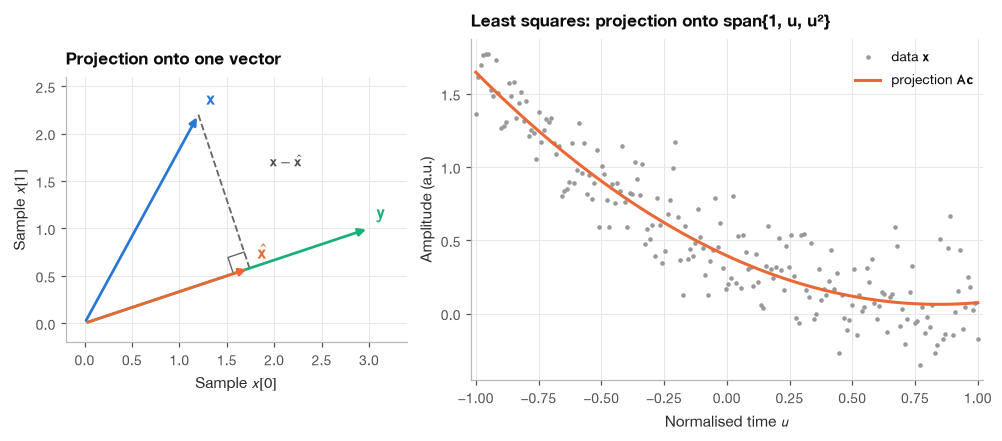

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.9), gridspec_kw={"width_ratios": [1, 1.5]})

ax = axes[0]
xv, yv = np.array([1.2, 2.2]), np.array([3.0, 1.0])
xhat = np.dot(xv, yv) / np.dot(yv, yv) * yv
for vec, col, lab in [(xv, C[0], r"$\mathbf{x}$"), (yv, C[2], r"$\mathbf{y}$"), (xhat, C[1], r"$\hat{\mathbf{x}}$")]:
    ax.annotate("", xy=vec, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=col, lw=1.8))
    ax.text(vec[0] + 0.08, vec[1] + 0.1, lab, color=col, fontsize=12)
ax.plot([xv[0], xhat[0]], [xv[1], xhat[1]], "--", color="0.4", lw=1.2)
ax.text(1.95, 1.65, r"$\mathbf{x} - \hat{\mathbf{x}}$", color="0.3", fontsize=10)
d = yv / np.linalg.norm(yv) * 0.18
e = (xv - xhat) / np.linalg.norm(xv - xhat) * 0.18
ax.plot([xhat[0] - d[0], xhat[0] - d[0] + e[0], xhat[0] + e[0]],
        [xhat[1] - d[1], xhat[1] - d[1] + e[1], xhat[1] + e[1]], color="0.4", lw=0.9)
ax.set(xlim=(-0.2, 3.4), ylim=(-0.2, 2.6), xlabel="Sample $x[0]$", ylabel="Sample $x[1]$",
       title="Projection onto one vector")
ax.set_aspect("equal")

ax = axes[1]
ax.plot(u, x, ".", color="0.6", ms=4, label="data $\\mathbf{x}$")
ax.plot(u, A @ c_normal, color=C[1], lw=2, label=r"projection $\mathbf{A}\mathbf{c}$")
ax.set(xlabel="Normalised time $u$", ylabel="Amplitude (a.u.)", title="Least squares: projection onto span{1, u, u²}")
ax.legend(loc="upper right")
plt.show()

(sec-2-2-5)=
## 2.2.5 Orthonormal Bases and Gram–Schmidt

The normal equations become trivial when the basis vectors are **orthonormal**, meaning mutually orthogonal and of unit length: $\langle \mathbf{q}_i, \mathbf{q}_k \rangle = 1$ if $i = k$ and $0$ otherwise. In matrix form $\mathbf{Q}^{\mathsf T}\mathbf{Q} = \mathbf{I}$, so the Gram matrix is the identity and equation [(2.9)](#eq-2-9) collapses to $\mathbf{c} = \mathbf{Q}^{\mathsf T}\mathbf{x}$. Each coefficient is a single inner product, computed independently of all the others:

(eq-2-10)=
\begin{equation*}
c_k = \langle \mathbf{x}, \mathbf{q}_k \rangle, \qquad \hat{\mathbf{x}} = \sum_{k} \langle \mathbf{x}, \mathbf{q}_k \rangle\, \mathbf{q}_k . \tag{2.10}
\end{equation*}

If the $\mathbf{q}_k$ form a complete basis of $\mathbb{R}^N$ (there are $N$ of them), the approximation is exact, $\hat{\mathbf{x}} = \mathbf{x}$, and taking the squared norm of both sides with the Pythagorean theorem applied term by term gives a finite-dimensional **Parseval relation**:

(eq-2-11)=
\begin{equation*}
\|\mathbf{x}\|^2 = \sum_{k} c_k^2 . \tag{2.11}
\end{equation*}

The energy of the signal equals the energy of its coefficients. Orthonormal transforms, including the DFT (after scaling) and the orthogonal wavelet transforms of [Chapter 14](../ch24_wavelets/index.md), redistribute energy among coefficients without creating or destroying any.

Two practical advantages follow. Adding one more basis vector does not change the coefficients already computed, so we can increase the order of an approximation one term at a time. And the computation is numerically safe: the Gram matrix of the plain monomials $1, u, u^2, \ldots, u^{12}$ on 3600 points has a condition number of about $3\times 10^{8}$, meaning that solving with it can lose eight of our sixteen decimal digits, while an orthonormal basis has condition number exactly one.

### The Gram–Schmidt procedure

Any set of linearly independent vectors $\mathbf{a}_1, \ldots, \mathbf{a}_p$ can be turned into an orthonormal set spanning the same subspace. The idea is to take the vectors in order and, from each new one, subtract its projections onto the directions already built, keeping only the part that is genuinely new:

(eq-2-12)=
\begin{equation*}
\mathbf{v}_k = \mathbf{a}_k - \sum_{i=1}^{k-1} \langle \mathbf{a}_k, \mathbf{q}_i \rangle\, \mathbf{q}_i, \qquad \mathbf{q}_k = \frac{\mathbf{v}_k}{\|\mathbf{v}_k\|}. \tag{2.12}
\end{equation*}

By equation [(2.8)](#eq-2-8), each subtracted term removes the component of $\mathbf{a}_k$ along one earlier $\mathbf{q}_i$, so $\mathbf{v}_k$ is orthogonal to all of them; dividing by its length makes it a unit vector. In floating point it is better to subtract the projections one at a time from the running remainder (the *modified* Gram–Schmidt procedure), which gives the same result in exact arithmetic but loses less orthogonality to rounding. We implement that version and compare it with NumPy's QR factorization, which computes the same orthonormal basis by a more stable method (Householder reflections). The columns may differ in sign, because $-\mathbf{q}_k$ is just as orthonormal as $\mathbf{q}_k$.

In [6]:
def gram_schmidt(A):
    """Orthonormalise the columns of A with modified Gram-Schmidt, equation (2.23)."""
    Q = np.array(A, dtype=float)
    for k in range(Q.shape[1]):
        for i in range(k):
            Q[:, k] -= np.dot(Q[:, k], Q[:, i]) * Q[:, i]
        Q[:, k] /= np.linalg.norm(Q[:, k])
    return Q

N = 400
u = np.linspace(-1, 1, N)
monomials = np.column_stack([u**k for k in range(5)])
Q = gram_schmidt(monomials)
Q_np, _ = np.linalg.qr(monomials)
signs = np.sign(np.sum(Q * Q_np, axis=0))

print(f"max |Q^T Q - I|                : {np.abs(Q.T @ Q - np.eye(5)).max():.2e}")
print(f"max difference from np.linalg.qr: {np.abs(Q - Q_np * signs).max():.2e}")
print(f"condition number of monomial Gram matrix : {np.linalg.cond(monomials.T @ monomials):.1f}")
print(f"condition number of orthonormal Gram matrix: {np.linalg.cond(Q.T @ Q):.1f}")

max |Q^T Q - I|                : 1.08e-15
max difference from np.linalg.qr: 1.44e-15
condition number of monomial Gram matrix : 353.6
condition number of orthonormal Gram matrix: 1.0


Applied to the powers $1, u, u^2, \ldots$ on a symmetric grid, Gram–Schmidt produces sampled versions of the **Legendre polynomials**, scaled to unit norm. They are drawn below. Notice how each new polynomial has one more zero crossing than the previous one, a pattern shared by every orthogonal family we will meet, sinusoids and wavelets included.

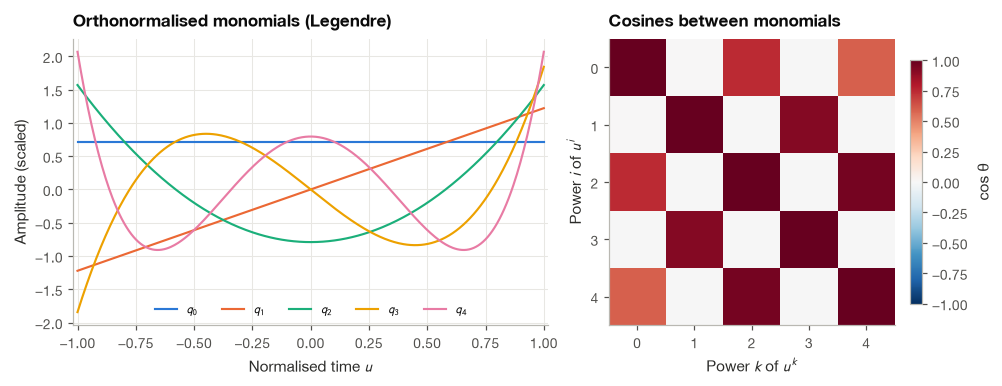

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
for k in range(5):
    ax.plot(u, Q[:, k] * np.sqrt(N / 2), color=C[k], label=f"$q_{k}$")
ax.set(xlabel="Normalised time $u$", ylabel="Amplitude (scaled)", title="Orthonormalised monomials (Legendre)")
ax.legend(ncol=5, loc="lower center", fontsize=8)

ax = axes[1]
G = monomials.T @ monomials
im = ax.imshow(G / np.sqrt(np.outer(np.diag(G), np.diag(G))), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set(xticks=range(5), yticks=range(5), xlabel="Power $k$ of $u^k$", ylabel="Power $i$ of $u^i$",
       title="Cosines between monomials")
ax.grid(False)
fig.colorbar(im, ax=ax, label="cos θ", shrink=0.85)
plt.show()

The right panel shows why the monomials are a poor basis: $u^2$ and $u^4$ point in almost the same direction (the cosine of the angle between them is close to 0.9), so the least-squares solver must separate two nearly parallel arrows, which is where the digits are lost.

(sec-2-2-6)=
## 2.2.6 Orthogonal Sinusoids and the Complex Inner Product

The most important orthogonal family in this book is the set of sinusoids that complete a whole number of cycles in the observation window. Consider $N$ samples and the cosines $c_k[n] = \cos(2\pi k n/N)$, which complete $k$ cycles in the window. We want the inner product $\langle c_k, c_m \rangle$ for integers $0 < k, m < N/2$.

**Step 1: turn the product into a sum.** The product-to-sum identity $\cos a\cos b = \tfrac{1}{2}[\cos(a - b) + \cos(a + b)]$ (add the angle-sum formulas for $\cos(a - b)$ and $\cos(a + b)$ from exercise 3 of [Section 2.1](01_complex_numbers.ipynb)) gives

$$
\langle c_k, c_m \rangle = \frac{1}{2}\sum_{n=0}^{N-1} \cos\!\Big(\frac{2\pi (k - m) n}{N}\Big) + \frac{1}{2}\sum_{n=0}^{N-1} \cos\!\Big(\frac{2\pi (k + m) n}{N}\Big).
$$

**Step 2: evaluate a sum of cosines over whole cycles.** For an integer $\ell$ that is not a multiple of $N$, the sum $\sum_n \cos(2\pi \ell n/N)$ is the real part of $\sum_n w^n$ with $w = e^{j2\pi\ell/N} \neq 1$. In [Section 2.1.5](01_complex_numbers.ipynb#sec-2-1-5) we showed with the geometric series that this sum is $(1 - w^N)/(1 - w) = 0$, because $w^N = e^{j2\pi\ell} = 1$. When $\ell = 0$ every term is $\cos 0 = 1$ and the sum is $N$.

**Step 3: combine.** Since $0 < k + m < N$, the second sum always vanishes. The first vanishes unless $k = m$, in which case it equals $N$. Therefore

(eq-2-13)=
\begin{equation*}
\sum_{n=0}^{N-1} \cos\!\Big(\frac{2\pi k n}{N}\Big)\cos\!\Big(\frac{2\pi m n}{N}\Big) = \begin{cases} N/2, & k = m, \\ 0, & k \neq m, \end{cases} \qquad 0 < k, m < \tfrac{N}{2}. \tag{2.13}
\end{equation*}

The same steps with $\sin a\cos b = \tfrac{1}{2}[\sin(a + b) + \sin(a - b)]$ show that every sine is orthogonal to every cosine in the family, including when $k = m$. In continuous time the sums become integrals over one period $T$, and $\int_0^T \cos(2\pi k t/T)\cos(2\pi m t/T)\,dt = (T/2)\,\delta_{km}$ by the same argument. These relations are the foundation of the Fourier series in [Chapter 5](../ch07_fourier_series/index.md).

The condition "whole number of cycles" matters. The cell below builds the Gram matrix of cosines at 1 to 6 cycles per window and compares it with cosines spaced 0.7 cycles apart (0.7, 1.4, ..., 4.2 cycles), most of which do not fit the window exactly.

largest off-diagonal cosine, whole cycles     : 1.68e-16
largest off-diagonal cosine, 0.7..4.2 cycles  : 0.231


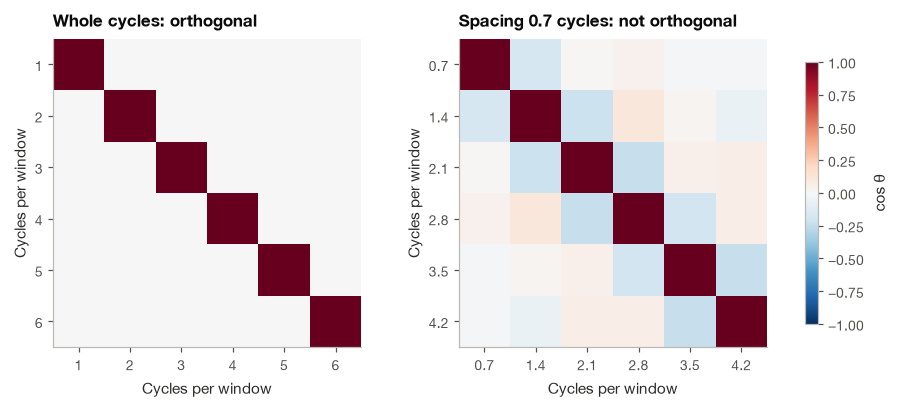

In [8]:
N = 360
n = np.arange(N)

def cosine_gram(cycles):
    """Normalised Gram matrix of cosines completing the given numbers of cycles in N samples."""
    B = np.column_stack([np.cos(2 * np.pi * k * n / N) for k in cycles])
    G = B.T @ B
    return G / np.sqrt(np.outer(np.diag(G), np.diag(G)))

G_whole = cosine_gram(np.arange(1, 7))
G_frac = cosine_gram(0.7 * np.arange(1, 7))
print(f"largest off-diagonal cosine, whole cycles     : {np.abs(G_whole - np.eye(6)).max():.2e}")
print(f"largest off-diagonal cosine, 0.7..4.2 cycles  : {np.abs(G_frac - np.eye(6)).max():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.6))
for ax, G, ttl, labels in [(axes[0], G_whole, "Whole cycles: orthogonal", np.arange(1, 7)),
                           (axes[1], G_frac, "Spacing 0.7 cycles: not orthogonal", np.round(0.7 * np.arange(1, 7), 1))]:
    im = ax.imshow(G, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set(xticks=range(6), yticks=range(6), xticklabels=labels, yticklabels=labels,
           xlabel="Cycles per window", ylabel="Cycles per window", title=ttl)
    ax.grid(False)
fig.colorbar(im, ax=axes, label="cos θ", shrink=0.85)
plt.show()

When the frequencies are spaced more closely than one cycle per window, neighbouring cosines are no longer perpendicular: the largest cosine between them is about 0.23, and the overlap decays only slowly with distance from the diagonal. This overlap is the vector-space face of **spectral leakage**, which we study in Section 10.4.

### Complex signals

For complex vectors the definition must change slightly. If we used $\sum x[n]y[n]$, the "squared length" of $\mathbf{x} = (j)$ would be $j^2 = -1$, which makes no sense. Conjugating the second argument fixes this:

(eq-2-14)=
\begin{equation*}
\langle \mathbf{x}, \mathbf{y} \rangle = \sum_{n=0}^{N-1} x[n]\,y^*[n], \qquad \langle \mathbf{x}, \mathbf{x} \rangle = \sum_{n=0}^{N-1} |x[n]|^2 \ge 0. \tag{2.14}
\end{equation*}

The price is that the inner product is no longer symmetric: $\langle \mathbf{y}, \mathbf{x} \rangle = \langle \mathbf{x}, \mathbf{y} \rangle^*$. Cauchy–Schwarz, projection and Gram–Schmidt carry over unchanged once this conjugate is respected. Using equation (2.14) with the complex exponentials $\mathbf{e}_k[n] = e^{j2\pi k n/N}$, the inner product is again a geometric series,

$$
\langle \mathbf{e}_k, \mathbf{e}_m \rangle = \sum_{n=0}^{N-1} e^{j2\pi (k - m) n/N} = \begin{cases} N, & k = m, \\ 0, & k \neq m, \end{cases} \qquad 0 \le k, m < N,
$$

so the $N$ complex exponentials form an orthogonal basis of $\mathbb{C}^N$, each of squared length $N$. By equation [(2.10)](#eq-2-10), the coefficient of $\mathbf{x}$ along $\mathbf{e}_k$ is $\langle \mathbf{x}, \mathbf{e}_k \rangle / N$, and the inner product itself is

(eq-2-15)=
\begin{equation*}
X[k] = \langle \mathbf{x}, \mathbf{e}_k \rangle = \sum_{n=0}^{N-1} x[n]\,e^{-j2\pi k n/N}. \tag{2.15}
\end{equation*}

This is the **discrete Fourier transform**. The "tuning dial" of [Section 2.1.7](01_complex_numbers.ipynb#sec-2-1-7) was an inner product all along, and the DFT is nothing more than the list of coordinates of a signal in the orthogonal basis of complex exponentials. Parseval's relation (2.11), adjusted for the squared length $N$, becomes $\sum_n |x[n]|^2 = \frac{1}{N}\sum_k |X[k]|^2$, which we verify on one second of ECG-like data.

In [9]:
x = qrs + hum + 0.02 * rng.standard_normal(qrs.size)
E_basis = np.exp(2j * np.pi * np.outer(n, n) / N)          # columns e_k[n]
X_inner = E_basis.conj().T @ x                             # inner products <x, e_k>, equation (2.26)
X_fft = np.fft.fft(x)

print(f"max |<x, e_k> - FFT|           : {np.abs(X_inner - X_fft).max():.2e}")
print(f"energy in time  sum |x|^2      : {np.sum(np.abs(x) ** 2):.4f} mV^2")
print(f"energy in coefficients /N      : {np.sum(np.abs(X_fft) ** 2) / N:.4f} mV^2")

max |<x, e_k> - FFT|           : 8.08e-13
energy in time  sum |x|^2      : 12.8605 mV^2
energy in coefficients /N      : 12.8605 mV^2


(sec-2-2-7)=
## 2.2.7 Finding Heartbeats by Template Matching

We now use the normalized inner product on a real recording. Record 100 of the MIT-BIH Arrhythmia Database {cite:p}`moody2001,goldberger2000` is 30 minutes of a two-lead ambulatory ECG sampled at 360 Hz, with every beat annotated by cardiologists. It is a clean record dominated by normal sinus beats, which makes it a good first test.

The plan is simple. Build a template $\mathbf{t}$ of a typical QRS complex, slide it along the recording, and at every position compute the correlation coefficient (2.7) between the template and the stretch of signal under it. Where a QRS complex lines up with the template, the two vectors point in almost the same direction and $\rho$ approaches one.

### Step 1: Load the record and its annotations

In [10]:
rec = wfdb.rdrecord("../data/mitdb/100")
ann = wfdb.rdann("../data/mitdb/100", "atr")
ecg, fs = rec.p_signal[:, 0], rec.fs                     # lead MLII, mV

beat_symbols = set("NLRBAaJSVrFejnE/fQ")
is_beat = np.array([s in beat_symbols for s in ann.symbol])
r_ref = ann.sample[is_beat]
sym_ref = np.array(ann.symbol)[is_beat]
print(f"{rec.sig_name[0]}: {ecg.size} samples at {fs} Hz ({ecg.size / fs / 60:.1f} min)")
print(f"annotated beats: {r_ref.size}  " + ", ".join(f"{s}: {np.sum(sym_ref == s)}" for s in np.unique(sym_ref)))

MLII: 650000 samples at 360 Hz (30.1 min)
annotated beats: 2273  A: 33, N: 2239, V: 1


### Step 2: Build a template from the first normal beats

Each annotation marks the R wave. We cut a window from 80 ms before to 120 ms after it, which covers the QRS complex (about 100 ms wide) with a little baseline on each side, and average the first 100 normal beats. Averaging suppresses noise that is not synchronized with the beat, an idea developed fully in [Section 10.1](../ch16_noise_removal/01_signal_averaging.ipynb). Subtracting the mean gives the centred template $\tilde{\mathbf{t}}$.

In [11]:
pre, post = int(0.08 * fs), int(0.12 * fs)
M = pre + post                                           # template length in samples
first_normals = r_ref[(sym_ref == "N") & (r_ref > pre)][:100]
segments = np.array([ecg[r - pre:r + post] for r in first_normals])
template = segments.mean(axis=0)
tc = template - template.mean()
print(f"template: {M} samples ({1000 * M / fs:.0f} ms), averaged over {len(segments)} beats")

template: 71 samples (197 ms), averaged over 100 beats


### Step 3: Compute the correlation coefficient at every position

A direct loop over 650,000 positions would recompute each window's mean and norm from scratch. Two observations make this fast. First, because $\tilde{\mathbf{t}}$ has zero mean, $\langle \mathbf{w} - \bar{w}\mathbf{1}, \tilde{\mathbf{t}} \rangle = \langle \mathbf{w}, \tilde{\mathbf{t}} \rangle - \bar{w}\,\langle \mathbf{1}, \tilde{\mathbf{t}} \rangle = \langle \mathbf{w}, \tilde{\mathbf{t}} \rangle$, so the numerator for every window $\mathbf{w}$ is a plain sliding inner product, which `np.correlate` computes. Second, the squared norm of a centred window can be expanded as

$$
\|\mathbf{w} - \bar{w}\mathbf{1}\|^2 = \sum_{m} w[m]^2 - 2\bar{w}\sum_m w[m] + M\bar{w}^2 = \sum_{m} w[m]^2 - \frac{1}{M}\Big(\sum_m w[m]\Big)^2 ,
$$

and both running sums are differences of cumulative sums. Sliding inner products are so common that they get their own name, **cross-correlation**, and Chapter 6 is devoted to them.

In [12]:
def sliding_corrcoef(x, template):
    """Correlation coefficient between template and every length-M window of x."""
    M = template.size
    tc = template - template.mean()
    num = np.correlate(x, tc, mode="valid")              # <w_i, tc> for every window i
    s1 = np.concatenate([[0.0], np.cumsum(x)])
    s2 = np.concatenate([[0.0], np.cumsum(x ** 2)])
    sum_w, sum_w2 = s1[M:] - s1[:-M], s2[M:] - s2[:-M]
    norm_w = np.sqrt(np.maximum(sum_w2 - sum_w ** 2 / M, 1e-12))
    return num / (norm_w * np.linalg.norm(tc))

rho = sliding_corrcoef(ecg, template)
i_check = r_ref[500] - pre
print(f"rho at beat 500 (fast)  : {rho[i_check]:.5f}")
print(f"rho at beat 500 (direct): {corr_coef(ecg[i_check:i_check + M], template):.5f}")

rho at beat 500 (fast)  : 0.99167
rho at beat 500 (direct): 0.99167


### Step 4: Pick the peaks and compare with the annotations

A beat is declared wherever $\rho$ has a local maximum above 0.8, with at least 250 ms between detections (a heart rate of 240 bpm, faster than anything in this record). Because the correlation at position $i$ describes the window that starts at $i$, the R wave sits at $i + 80$ ms. A detection counts as correct when it falls within 50 ms of an annotated beat.

In [13]:
peaks, _ = signal.find_peaks(rho, height=0.8, distance=int(0.25 * fs))
r_det = peaks + pre

def match_beats(detected, reference, tol):
    """Return a boolean array: is each reference beat within tol samples of a detection?"""
    j = np.clip(np.searchsorted(detected, reference), 1, detected.size - 1)
    nearest = np.minimum(np.abs(detected[j] - reference), np.abs(detected[j - 1] - reference))
    return nearest <= tol

found = match_beats(r_det, r_ref, tol=int(0.05 * fs))
tp = found.sum()
fp = r_det.size - tp
print(f"detections: {r_det.size}, reference beats: {r_ref.size}")
print(f"sensitivity = {tp / r_ref.size:.4f}, positive predictivity = {tp / (tp + fp):.4f}")
print("missed beats:", [(int(s), str(sym)) for s, sym in zip(r_ref[~found], sym_ref[~found])])
v_idx = r_ref[sym_ref == "V"][0] - pre
print(f"rho at the ventricular beat: {rho[v_idx]:.2f}")

detections: 2271, reference beats: 2273
sensitivity = 0.9991, positive predictivity = 1.0000
missed beats: [(546792, 'V'), (649991, 'N')]
rho at the ventricular beat: -0.72


Only two of the 2273 annotated beats are missed and there are no false detections. The second miss is the very last beat of the file, too close to the end for a full window to fit. The first is the single premature ventricular beat (`V`) in the record. Its correlation with the template is strongly negative, as the next figure shows: a ventricular beat starts in the ventricle rather than travelling down the normal conduction pathway, so its QRS complex is wide and, in this lead, points the other way. In this application the "failure" is useful information. A beat that is clearly a heartbeat but correlates poorly with the patient's normal template is exactly what an arrhythmia monitor should flag, an idea we use in Section 6.2 and Section 19.4.

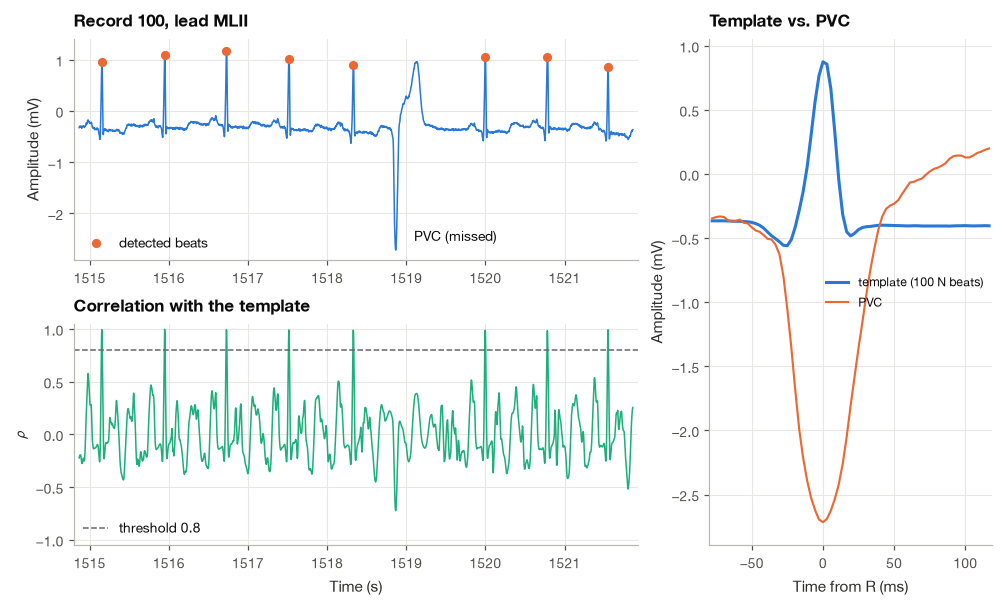

In [14]:
v_beat = r_ref[sym_ref == "V"][0]
fig = plt.figure(figsize=(9, 5.4))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 1])
ax0 = fig.add_subplot(gs[0, :2])
ax1 = fig.add_subplot(gs[1, :2], sharex=ax0)
ax2 = fig.add_subplot(gs[:, 2])

a, b = v_beat - 4 * fs, v_beat + 3 * fs
tt = np.arange(a, b) / fs
ax0.plot(tt, ecg[a:b], color=C[0], lw=1)
sel = (r_det > a) & (r_det < b)
ax0.plot(r_det[sel] / fs, ecg[r_det[sel]], "o", color=C[1], ms=5, label="detected beats")
ax0.annotate("PVC (missed)", (v_beat / fs, ecg[v_beat]), textcoords="offset points", xytext=(12, 6), fontsize=9)
ax0.set(ylabel="Amplitude (mV)", title="Record 100, lead MLII")
ax0.legend(loc="lower left")

ax1.plot(tt, rho[a - pre:b - pre], color=C[2], lw=1)           # rho[i] describes the beat at i + pre
ax1.axhline(0.8, color="0.4", ls="--", lw=1, label="threshold 0.8")
ax1.set(xlabel="Time (s)", ylabel=r"$\rho$", ylim=(-1.05, 1.05), title="Correlation with the template")
ax1.legend(loc="lower left")

tm = (np.arange(M) - pre) / fs * 1000
ax2.plot(tm, template, color=C[0], lw=2, label="template (100 N beats)")
ax2.plot(tm, ecg[v_beat - pre:v_beat + post], color=C[1], lw=1.4, label="PVC")
ax2.set(xlabel="Time from R (ms)", ylabel="Amplitude (mV)", title="Template vs. PVC")
ax2.legend(loc="center right", fontsize=8)
plt.show()

The method has obvious limitations, and I want to name them before we rely on it. The template must come from the same patient and lead, because QRS shape differs a great deal between people and between leads. The threshold of 0.8 was chosen by eye on a clean record, and a noisy record would need a lower one at the price of more false detections. Dedicated QRS detectors such as the Pan–Tompkins algorithm of Section 19.1 are designed to work without a patient-specific template. Still, a few dozen lines of code have taken us from the definition of an inner product to a beat detector with a sensitivity above 99.9% on this record.

(sec-2-2-8)=
## 2.2.8 Removing Baseline Wander by Projection

Breathing, body movement and changes in electrode–skin contact make the ECG baseline drift slowly up and down. This **baseline wander** has most of its energy below about 0.5 Hz, while the clinically important ECG content lies above it. The noise stress test database {cite:p}`moody1984` provides real baseline wander recorded from a volunteer with the electrodes placed so that no ECG was picked up, which lets us add a known disturbance to a clean ECG and measure how well we remove it.

The projection idea is direct. Over a short window, a slowly drifting curve is well described by a low-order polynomial, so it lies (nearly) in the subspace spanned by $1, u, u^2, \ldots, u^p$. The ECG, with its sharp QRS complexes, is mostly orthogonal to that subspace. Projecting the noisy recording onto the polynomial subspace with equation [(2.9)](#eq-2-9) therefore estimates the wander, and subtracting the projection removes it.

### Step 1: Add real baseline wander to a clean segment

In [15]:
start, dur = 300, 10                                     # seconds
a, b = start * fs, (start + dur) * fs
clean = ecg[a:b]
bw = wfdb.rdrecord("../data/nstdb/bw", sampfrom=a, sampto=b).p_signal[:, 0]
noisy = clean + bw
t = np.arange(clean.size) / fs
u = 2 * t / t[-1] - 1                                    # map the window onto [-1, 1]

def rms(x):
    """Root-mean-square value."""
    return np.sqrt(np.mean(x ** 2))

target = clean - clean.mean()
print(f"baseline wander: peak-to-peak {np.ptp(bw):.2f} mV")
print(f"RMS error before correction: {rms(noisy - noisy.mean() - target):.3f} mV")

baseline wander: peak-to-peak 1.40 mV
RMS error before correction: 0.356 mV


### Step 2: Project onto polynomials of increasing degree

We solve the normal equations for degrees 1 to 12. I map time to $[-1, 1]$ before forming the powers; on the raw time axis in seconds, $t^{12}$ would reach $10^{12}$ and the Gram matrix would be hopelessly ill-conditioned. To guard against the conditioning issue noted in [Section 2.2.5](#sec-2-2-5), we also compute each fit with the orthonormal basis from `gram_schmidt` and check that both routes agree.

In [16]:
def polynomial_baseline(x, u, degree):
    """Project x onto span{1, u, ..., u^degree} with the normal equations (2.20)."""
    A = np.vander(u, degree + 1, increasing=True)
    c = np.linalg.solve(A.T @ A, A.T @ x)
    return A @ c

rows = []
for p in (1, 2, 4, 6, 8, 10, 12):
    base = polynomial_baseline(noisy, u, p)
    Qp = gram_schmidt(np.vander(u, p + 1, increasing=True))
    base_q = Qp @ (Qp.T @ noisy)                         # equation (2.21)
    rows.append({"degree": p, "RMS error (mV)": rms(noisy - base - target),
                 "normal eq. vs Q basis (mV)": np.abs(base - base_q).max()})
results = pd.DataFrame(rows).set_index("degree")
print(results.to_string(formatters={"RMS error (mV)": "{:.3f}".format,
                                    "normal eq. vs Q basis (mV)": "{:.1e}".format}))
A12 = np.vander(u, 13, increasing=True)
print(f"condition number of the degree-12 Gram matrix: {np.linalg.cond(A12.T @ A12):.1e}")

       RMS error (mV) normal eq. vs Q basis (mV)
degree                                          
1               0.307                    5.6e-16
2               0.236                    1.6e-15
4               0.151                    9.9e-15
6               0.088                    8.8e-14
8               0.059                    5.0e-12
10              0.046                    9.6e-11
12              0.044                    4.2e-10
condition number of the degree-12 Gram matrix: 2.9e+08


The error falls quickly up to degree 8 and then levels off. The last column is a small lesson in numerical linear algebra: the two routes agree to about $10^{-16}$ mV for a straight line, but the disagreement grows by six orders of magnitude as the Gram matrix of the monomials approaches a condition number of $3 \times 10^{8}$. The orthonormal route is the trustworthy one. A degree-$p$ polynomial over a 10 s window can follow oscillations of roughly $p/2$ cycles per window, so degree 8 tracks drift up to about 0.4 Hz, which covers most of the respiratory band. Going higher buys little, because the polynomial then starts to bend toward the slow parts of the ECG itself (the T waves), which are not orthogonal to the polynomial subspace.

### Step 3: Look at the result

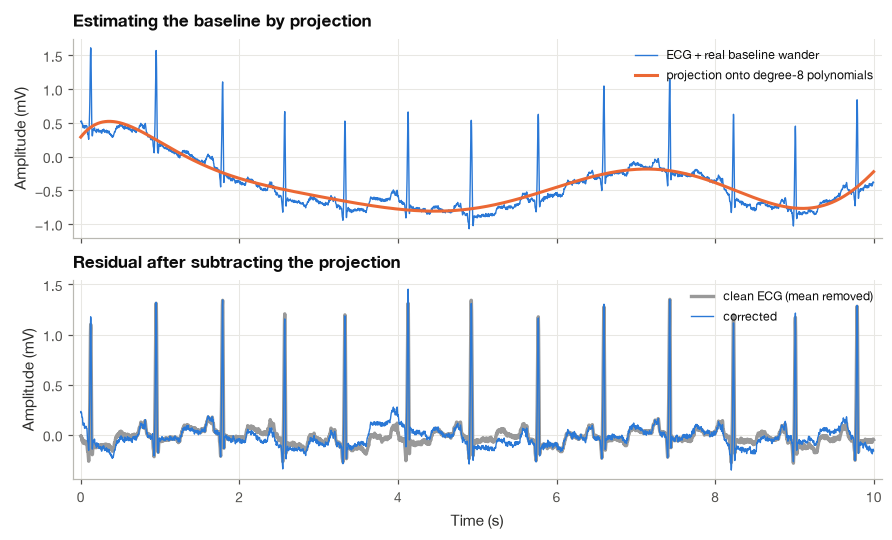

In [17]:
base8 = polynomial_baseline(noisy, u, 8)
corrected = noisy - base8

fig, axes = plt.subplots(2, 1, figsize=(8, 4.8), sharex=True)
axes[0].plot(t, noisy, color=C[0], lw=0.9, label="ECG + real baseline wander")
axes[0].plot(t, base8, color=C[1], lw=2, label="projection onto degree-8 polynomials")
axes[0].set(ylabel="Amplitude (mV)", title="Estimating the baseline by projection")
axes[0].legend(loc="upper right", fontsize=8)

axes[1].plot(t, target, color="0.6", lw=2.2, label="clean ECG (mean removed)")
axes[1].plot(t, corrected, color=C[0], lw=0.9, label="corrected")
axes[1].set(xlabel="Time (s)", ylabel="Amplitude (mV)", title="Residual after subtracting the projection")
axes[1].legend(loc="upper right", fontsize=8)
plt.show()

The corrected trace follows the clean ECG closely. The remaining error is concentrated in the slow parts of the ECG, as we would expect from the geometry: whatever portion of the true ECG lies inside the polynomial subspace is removed along with the wander. In practice this method is applied in overlapping windows, or replaced by splines fitted through isoelectric points in the PR segments, and [Section 12.2](../ch18_ecg_preprocessing/02_highpass_baseline_wander.ipynb) compares these approaches with high-pass filtering.

## Summary

A finite signal is a vector in $\mathbb{R}^N$ (or $\mathbb{C}^N$), and the inner product $\langle \mathbf{x}, \mathbf{y} \rangle = \sum_n x[n]y^*[n]$ gives it a geometry. The squared norm is the signal's energy, orthogonal signals have energies that add, and the Cauchy–Schwarz inequality, which we proved by minimizing the error of a scaled approximation, guarantees that the cosine of the angle between two signals lies in $[-1, 1]$. After centring, that cosine is the correlation coefficient, a measure of shape that ignores gain and offset. The same minimization, generalized to several directions, gives the orthogonality principle and the normal equations of least squares, and Gram–Schmidt turns any basis into an orthonormal one in which every coefficient is a single inner product and energy is preserved.

Sinusoids that complete whole cycles in the window are mutually orthogonal, and complex exponentials form an orthogonal basis whose coordinates are the DFT. On record 100, a normalized inner product with a QRS template found 2271 of 2273 beats, and projection onto degree-8 polynomials reduced the error caused by real baseline wander several-fold. Correlation (Chapter 6), the Fourier series and transform ([Chapters 5](../ch07_fourier_series/index.md) to 10), the Wiener filter ([Section 10.2](../ch16_noise_removal/02_wiener_filter.ipynb)), wavelets and principal component analysis (Chapter 25) are all built on these ideas.

## Exercises

1. Let $\mathbf{x} = (1, 2, 2)^{\mathsf T}$ and $\mathbf{y} = (2, 0, -1)^{\mathsf T}$. Compute $\langle \mathbf{x}, \mathbf{y} \rangle$, both norms, the angle between them in degrees, and the projection of $\mathbf{x}$ onto $\mathbf{y}$. Verify that the residual is orthogonal to $\mathbf{y}$, by hand and in NumPy.
2. Prove the triangle inequality $\|\mathbf{x} + \mathbf{y}\| \le \|\mathbf{x}\| + \|\mathbf{y}\|$ by expanding $\|\mathbf{x} + \mathbf{y}\|^2$ and applying Cauchy–Schwarz. What does it imply for the RMS value of an ECG plus noise?
3. Show that the correlation coefficient $\rho_{xy}$ is unchanged if $\mathbf{x}$ is replaced by $a\mathbf{x} + b\mathbf{1}$ with $a > 0$, and that its sign flips if $a < 0$. Why is this a desirable property for comparing heartbeats recorded with different amplifier gains?
4. Repeat the derivation of equation (2.13) for $\sum_n \sin(2\pi k n/N)\cos(2\pi m n/N)$ and show that it is zero for all integers $0 < k, m < N/2$. Then check numerically what happens when $k + m = N$.
5. Apply Gram–Schmidt by hand to $\mathbf{a}_1 = (1, 1, 1, 1)^{\mathsf T}$, $\mathbf{a}_2 = (0, 1, 2, 3)^{\mathsf T}$ and compare with `gram_schmidt`. Then construct an example of three vectors for which the classical (not modified) algorithm loses orthogonality noticeably in floating point (hint: make the vectors nearly parallel, e.g. $(1, \epsilon, 0, 0)$, $(1, 0, \epsilon, 0)$, $(1, 0, 0, \epsilon)$ with $\epsilon = 10^{-8}$).
6. Run the template detector of [Section 2.2.7](#sec-2-2-7) on record 105, which contains heavy noise. Build the template from that record, report sensitivity and positive predictivity for thresholds 0.6, 0.7 and 0.8, and plot a segment where false detections occur. Explain the failures in terms of angles between vectors.

## Further Reading

{cite:t}`strang2016` develops inner products, projections, least squares and Gram–Schmidt with exactly the geometric emphasis used here, and it is the book I recommend for anyone who wants more linear algebra. {cite:t}`smith1997` and {cite:t}`proakis2007` present the DFT as a change to an orthogonal basis, while {cite:t}`sornmo2005` discusses template matching and correlation-based beat classification for the ECG in depth. The MIT-BIH and noise stress test databases are described in {cite:t}`moody2001` and {cite:t}`moody1984` and distributed through PhysioNet {cite:p}`goldberger2000`.